In [166]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



df = pd.read_csv("Bank_transaction_scenario1.csv", sep=";")

# Drop the columns that are not useful for modeling

df.drop(columns=["ID Clients", "Numero de compte", "Identifiant operation"], inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5382 entries, 0 to 5381
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Type de transaction  5382 non-null   object 
 1   Status operation     5382 non-null   object 
 2   Localisation         5382 non-null   object 
 3   Date                 5382 non-null   object 
 4   Montant              5382 non-null   float64
 5   Target               5382 non-null   object 
dtypes: float64(1), object(5)
memory usage: 252.4+ KB


In [167]:
df.describe(include="all")

,Type de transaction,Status operation,Localisation,Date,Montant,Target
count,5382,5382,5382,5382,5.382000e+03,5382
unique,3,3,50,3995,NaN,3
top,ATM,Validé,Dakar,2024-05-01 10:00:00,NaN,Normal
freq,1937,3612,952,17,NaN,4093
mean,NaN,NaN,NaN,NaN,2.911279e+05,NaN
std,NaN,NaN,NaN,NaN,1.127725e+06,NaN
min,NaN,NaN,NaN,NaN,1.000000e+03,NaN
25%,NaN,NaN,NaN,NaN,1.000000e+04,NaN
50%,NaN,NaN,NaN,NaN,4.900000e+04,NaN
75%,NaN,NaN,NaN,NaN,1.500000e+05,NaN


In [168]:
print(df["Target"].value_counts())
print(df["Type de transaction"].value_counts())
print(df["Status operation"].value_counts())


Target
Normal     4093
Suspect    1091
Fraude      198
Name: count, dtype: int64
Type de transaction
ATM                      1937
Paiement en ligne        1740
Paiement électronique    1705
Name: count, dtype: int64
Status operation
Validé        3612
Echoué         902
En attente     868
Name: count, dtype: int64


In [169]:
print(df["Localisation"].value_counts)

<bound method IndexOpsMixin.value_counts of 0           Kaolack
1       Tambacounda
2             Thiès
3           Kaolack
4        Ziguinchor
           ...     
5377          Dakar
5378       Diourbel
5379     Ziguinchor
5380        Kaolack
5381    Tambacounda
Name: Localisation, Length: 5382, dtype: object>


In [170]:
# Transform the Target column to binary (0 for Normal, 1 for Fraude)

df["Target"] = df["Target"].replace("Suspect", "Fraude")
df["Target"] = df["Target"].apply(lambda x: 1 if x == "Fraude" else 0)
print(df["Target"].value_counts())

Target
0    4093
1    1289
Name: count, dtype: int64


In [171]:
# Transformer la colonne "Date operation" en format datetime et extraire les caractéristiques temporelles

df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d %H:%M:%S")

df["Hour"] = df["Date"].dt.hour
df["Month"] = df["Date"].dt.month
df["DayOfWeek"] = df["Date"].dt.dayofweek
df["IsWeekend"] = df["DayOfWeek"].apply(lambda x: 1 if x >= 5 else 0)

df.drop(columns=["Date"], inplace=True)


# fréquence de chaque localisation
freq_loc = df["Localisation"].value_counts(normalize=True)

# mapper la fréquence sur chaque ligne
df["freq_loc"] = df["Localisation"].map(freq_loc)

# One hot encode the categorical features "Type de transaction", "Status operation", "Localisation"

df = pd.get_dummies(df, columns=["Type de transaction", "Status operation", "Localisation"])

df1 = df.drop(columns=["Montant", "Target", "Hour", "Month", "DayOfWeek", "IsWeekend", "freq_loc"])
df2 = df[["Montant", "Hour", "Month", "DayOfWeek", "IsWeekend", "freq_loc"]]

df1 = df1.astype(np.int32)

df = pd.concat([df2, df1, df["Target"]], axis=1)

df.to_csv("Bank_transaction_scenario1_processed.csv", index=False)


In [172]:
print(df.shape)

(5382, 63)


In [173]:
df.info()
df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5382 entries, 0 to 5381
Data columns (total 63 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Montant                                    5382 non-null   float64
 1   Hour                                       5382 non-null   int32  
 2   Month                                      5382 non-null   int32  
 3   DayOfWeek                                  5382 non-null   int32  
 4   IsWeekend                                  5382 non-null   int64  
 5   freq_loc                                   5382 non-null   float64
 6   Type de transaction_ATM                    5382 non-null   int32  
 7   Type de transaction_Paiement en ligne      5382 non-null   int32  
 8   Type de transaction_Paiement électronique  5382 non-null   int32  
 9   Status operation_Echoué                    5382 non-null   int32  
 10  Status operation_En atte

,Montant,Hour,Month,DayOfWeek,IsWeekend,freq_loc,Type de transaction_ATM,Type de transaction_Paiement en ligne,Type de transaction_Paiement électronique,Status operation_Echoué,...,Localisation_Saloum,Localisation_Sédhiou,Localisation_Tambacounda,Localisation_Thiès,Localisation_Tivaouane,Localisation_Touba,Localisation_Toubacouta,Localisation_Vélingara,Localisation_Ziguinchor,Target
count,5.382000e+03,5382.000000,5382.000000,5382.000000,5382.000000,5382.000000,5382.000000,5382.00000,5382.000000,5382.000000,...,5382.000000,5382.000000,5382.000000,5382.000000,5382.000000,5382.000000,5382.000000,5382.000000,5382.000000,5382.000000
mean,2.911279e+05,12.526013,7.375697,3.017837,0.285210,0.084390,0.359903,0.32330,0.316797,0.167596,...,0.000929,0.012635,0.091416,0.105165,0.012077,0.012449,0.001115,0.005203,0.080825,0.239502
std,1.127725e+06,3.156274,2.846776,2.004005,0.451556,0.054232,0.480016,0.46778,0.465271,0.373542,...,0.030469,0.111702,0.288226,0.306795,0.109241,0.110888,0.033374,0.071947,0.272591,0.426819
min,1.000000e+03,0.000000,1.000000,0.000000,0.000000,0.000372,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000e+04,10.000000,6.000000,1.000000,0.000000,0.031401,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4.900000e+04,12.000000,7.000000,3.000000,0.000000,0.085098,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.500000e+05,15.000000,9.000000,5.000000,1.000000,0.105165,1.000000,1.00000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.500000e+07,23.000000,12.000000,6.000000,1.000000,0.176886,1.000000,1.00000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [174]:
print(df.head())

    Montant  Hour  Month  DayOfWeek  IsWeekend  freq_loc  \
0   45000.0    22      2          0          0  0.085098   
1   18000.0    17      2          0          0  0.091416   
2  200000.0     3      2          0          0  0.105165   
3   29000.0     9      2          6          1  0.085098   
4   14000.0    15      2          5          1  0.080825   

   Type de transaction_ATM  Type de transaction_Paiement en ligne  \
0                        0                                      1   
1                        1                                      0   
2                        0                                      0   
3                        1                                      0   
4                        1                                      0   

   Type de transaction_Paiement électronique  Status operation_Echoué  ...  \
0                                          0                        1  ...   
1                                          0                        

In [175]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Log-transform Montant

df = df.copy()
df["Montant_log"] = np.log1p(df["Montant"])

#retirer Montant brut pour éviter redondance
df = df.drop(columns=["Montant"])


#Split stratifié (train/val/test)

X = df.drop(columns=["Target"])
y = df["Target"].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)


# scale seulement les colonnes numériques continues

num_cols = ["Montant_log", "freq_loc", "Hour", "Month", "DayOfWeek"]  # adapte si tu supprimes/ajoutes des colonnes

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols]   = scaler.transform(X_val[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])


print("Shapes:", X_train.shape, X_val.shape, X_test.shape)
print("Target counts train:", y_train.value_counts().to_dict())

Shapes: (4305, 62) (538, 62) (539, 62)
Target counts train: {0: 3274, 1: 1031}


In [176]:
import torch
import torch.nn as nn
import torch.optim as optim

class MLPbinaire(nn.Module):
    def __init__(self, input_dim, dropout = 0.1):
        super(MLPbinaire, self).__init__()
        self.fc1 = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout))
        self.fc2 = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout))
        self.fc3 = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout))
        self.fc4 = nn.Linear(32, 1)
    
        
    def forward(self, x):
        x = self.fc1(x)
        x = self.fc2(x)
        x = self.fc3(x)
        x = self.fc4(x)
        return x
    
    
model = MLPbinaire(input_dim=X_train.shape[1], dropout=0.1)

print(model)
    
# Convertir les données en tensors PyTorch

X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)

X_val_tensor = torch.tensor(X_val.values, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)

X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

MLPbinaire(
  (fc1): Sequential(
    (0): Linear(in_features=62, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
  )
  (fc2): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
  )
  (fc3): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
  )
  (fc4): Linear(in_features=32, out_features=1, bias=True)
)


In [177]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_tensor, y_val_tensor), batch_size=256, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_tensor, y_test_tensor), batch_size=256, shuffle=False)

In [178]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MLPbinaire(input_dim=X_train.shape[1]).to(device)

pos_weight = torch.tensor([4093/1289]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [179]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss = 0

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            logits = model(xb)
            loss = criterion(logits, yb)

            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * xb.size(0)

    return total_loss / len(loader.dataset)

In [180]:
best_val = float("inf")
patience, wait = 20, 0
best_state = None

train_losses, val_losses = [], []

for epoch in range(1, 301):

    train_loss = run_epoch(train_loader, train=True)
    val_loss   = run_epoch(val_loader, train=False)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val - 1e-5:
        best_val = val_loss
        best_state = model.state_dict()
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping")
            break

    print(f"Epoch {epoch} | Train {train_loss:.4f} | Val {val_loss:.4f}")

model.load_state_dict(best_state)

Epoch 1 | Train 0.9712 | Val 0.7601
Epoch 2 | Train 0.7460 | Val 0.7155
Epoch 3 | Train 0.7053 | Val 0.7114
Epoch 4 | Train 0.6840 | Val 0.7040
Epoch 5 | Train 0.6589 | Val 0.7063
Epoch 6 | Train 0.6368 | Val 0.7102
Epoch 7 | Train 0.6193 | Val 0.7096
Epoch 8 | Train 0.6124 | Val 0.7397
Epoch 9 | Train 0.6048 | Val 0.7320
Epoch 10 | Train 0.5891 | Val 0.7134
Epoch 11 | Train 0.5751 | Val 0.7462
Epoch 12 | Train 0.5717 | Val 0.7449
Epoch 13 | Train 0.5569 | Val 0.7351
Epoch 14 | Train 0.5531 | Val 0.7405
Epoch 15 | Train 0.5402 | Val 0.7501
Epoch 16 | Train 0.5290 | Val 0.7370
Epoch 17 | Train 0.5223 | Val 0.7712
Epoch 18 | Train 0.5247 | Val 0.7859
Epoch 19 | Train 0.5091 | Val 0.7646
Epoch 20 | Train 0.5015 | Val 0.7846
Epoch 21 | Train 0.4973 | Val 0.7929
Epoch 22 | Train 0.5077 | Val 0.7834
Epoch 23 | Train 0.4863 | Val 0.8035
Early stopping


<All keys matched successfully>

In [184]:
model.eval()
y_true, y_pred, y_prob = [], [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        logits = model(xb)

        probs = torch.sigmoid(logits)

        y_prob.extend(probs.cpu().numpy())
        y_pred.extend((probs > 0.5).int().cpu().numpy())
        y_true.extend(yb.numpy())

In [185]:
import numpy as np
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    precision_score, roc_auc_score, confusion_matrix, classification_report
)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("Accuracy :", accuracy_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))
print("Recall fraude :", recall_score(y_true, y_pred))
print("Precision :", precision_score(y_true, y_pred))
print("ROC-AUC :", roc_auc_score(y_true, y_prob))

print("\nClassification report\n")
print(classification_report(y_true, y_pred))

print("\nConfusion matrix\n")
print(confusion_matrix(y_true, y_pred))

Accuracy : 0.8293135435992579
F1-score : 0.7032258064516129
Recall fraude : 0.8449612403100775
Precision : 0.6022099447513812
ROC-AUC : 0.903044053696351

Classification report

              precision    recall  f1-score   support

         0.0       0.94      0.82      0.88       410
         1.0       0.60      0.84      0.70       129

    accuracy                           0.83       539
   macro avg       0.77      0.83      0.79       539
weighted avg       0.86      0.83      0.84       539


Confusion matrix

[[338  72]
 [ 20 109]]


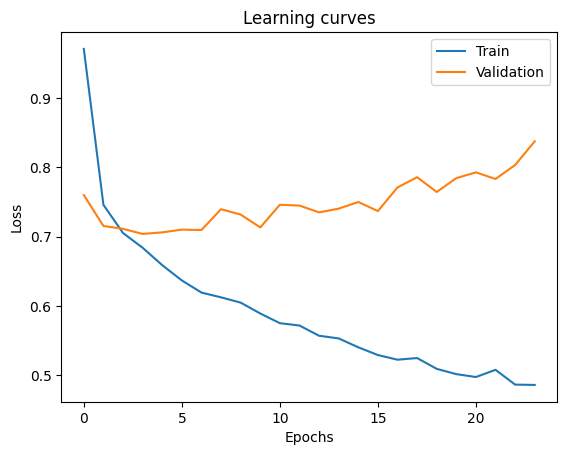

In [186]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.title("Learning curves")
plt.show()